# 02 · Multi-year indicators: estimation, uncertainty and trend models

**Author:** Yike SHI

**Question 2 of the brief.** We define four indicators, estimate them for every year
2014–2025 with confidence intervals, and quantify their temporal trends with a sequence of
linear regression models that are compared and criticised.

Input: the clean tables written by notebook 01 (`data/processed/`).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy import stats

from src import config as C, indices as I, models as M, plots

plots.set_style()
pd.set_option("display.width", 160)
B_INDEX = 2000      # bootstrap replicates for annual indices (percentile CIs need many)
B_COEF = 1000       # bootstrap replicates for regression coefficients
LEVEL = 0.95

records = pd.read_csv(C.PROCESSED_DIR / "records.csv.gz", low_memory=False)
visits = pd.read_csv(C.PROCESSED_DIR / "visits.csv", parse_dates=["date"])
point_visits = pd.read_csv(C.PROCESSED_DIR / "point_visits.csv.gz")
rec = records[records["is_record"] == True].copy()
rec["is_species"] = rec["is_species"].astype(bool)
print(f"{len(visits)} visits, {len(point_visits)} point counts, {len(rec)} bird records")

1420 visits, 14128 point counts, 112309 bird records


## 1. The four indicators and why

| # | Indicator | Definition (per year) | Why this indicator |
|---|---|---|---|
| 1 | **Community abundance index** | individuals counted / point counts surveyed (seabirds and fly-overs excluded), also as base-100 (2014 = 100) | The standardised index recommended in the brief: comparable across years with unequal effort. Seabirds are excluded because a few colony counts on two islets (up to 200 birds) would dominate the community total. |
| 2 | **Local species richness** | mean number of species per complete visit (10 points) | Diversity as experienced at one site; effort is fixed by protocol (complete visits only). |
| 3 | **Equal-effort island richness** | expected number of species found in *m* = 60 visits (rarefaction) | The raw number of species found in a year is a *biased* estimator of diversity: it grows with the number of visits. Rarefaction removes this effort bias (at the cost of some variance). |
| 4 | **Community composition** | share of individuals belonging to endemic and to exotic species | Conservation-relevant: biodiversity can change in *who* is there even if totals do not. |

Observation effort itself (visits, transects, observers) is described in notebook 01. It has no
sampling uncertainty (it is a census of what was done), so it is used to standardise and to
explain the indicators rather than as an indicator with a confidence interval.

In [2]:
# Community records: exclude seabirds (colonies on islets); fly-overs are already in a separate column.
comm = rec[rec["status_group"].ne("Seabird")]
pt = comm.groupby(["visit_id", "point"]).agg(n=("count", "sum"), n50=("count_lt50", "sum")).reset_index()
pv = point_visits[["visit_id", "point", "transect", "year"]].merge(pt, on=["visit_id", "point"], how="left")
pv[["n", "n50"]] = pv[["n", "n50"]].fillna(0)      # a point with no (non-seabird) bird is a true 0
pv["one"] = 1.0                                      # effort: one point count

# Visit-level table for the models
wx = (records.drop_duplicates(["visit_id", "point"]).groupby("visit_id")
      .agg(rain_share=("rain", lambda s: (s >= 2).mean()), wind_share=("wind", lambda s: (s == 3).mean())))
v = visits.merge(pv.groupby("visit_id")[["n", "n50"]].sum().reset_index(), on="visit_id").merge(wx, on="visit_id", how="left")
v["y"] = np.log(v["n"] / v["n_points"])              # log(individuals per point count)
v["y50"] = np.log(v["n50"] / v["n_points"])          # same, birds within 50 m only
v["doy_c"] = v["doy"] - v["doy"].mean()               # centred day of year
v["start_h"] = ((v["start_min"] - 360) / 60).fillna(((v["start_min"] - 360) / 60).median())  # hours after 06:00
v["p2"] = (v["passage"] == 2).astype(float)
v[["rain_share", "wind_share"]] = v[["rain_share", "wind_share"]].fillna(0)
v["log_prev_seasons"] = np.log1p(v["obs_prev_seasons"])
v["first_season"] = v["obs_first_season"].astype(float)
COND = ["doy_c", "start_h", "p2", "rain_share", "wind_share"]

assert np.isclose(pv["n"].sum(), comm["count"].sum()), "point totals must match record totals"
assert np.isfinite(v["y"]).all(), "every visit has at least one bird, so the log is defined"
print(f"Seabird individuals excluded: {int(rec.loc[rec['status_group'].eq('Seabird'), 'count'].sum())} "
      f"({rec.loc[rec['status_group'].eq('Seabird'), 'count'].sum() / rec['count'].sum():.1%} of all)")

Seabird individuals excluded: 2783 (1.1% of all)


## 2. Putting a confidence interval on an annual index

### 2.1 The estimator
For year *t*, let $Y_{i}$ be the number of individuals at point count *i* and $n_t$ the number of
point counts. The index is $\hat\lambda_t = \frac{1}{n_t}\sum_i Y_i$. If the $Y_i$ were i.i.d.
Poisson($\lambda_t$), this is both the **MLE and the method-of-moments estimator** of $\lambda_t$;
it is unbiased and consistent (LLN), and its Fisher-information standard error is
$\sqrt{\hat\lambda_t / n_t}$ (the Cramér–Rao bound). Before using that formula we check its two
assumptions: **Poisson** and **independence**.

### 2.2 Is the Poisson model adequate?

In [3]:
y25 = pv.loc[pv["year"] == 2025, "n"].to_numpy()
m_, s2_ = y25.mean(), y25.var(ddof=1)
k_mom = m_ ** 2 / (s2_ - m_)          # method of moments for a Negative-Binomial size parameter
print(f"2025 point counts: mean {m_:.2f}, variance {s2_:.1f}, variance/mean = {s2_ / m_:.1f} (Poisson: 1)")
print(f"Method-of-moments estimate of the extra-Poisson dispersion: k = mean^2/(var-mean) = {k_mom:.1f} "
      f"(variance = mean + mean^2/k)")
print(f"P(count >= 40): observed {np.mean(y25 >= 40):.3%}, Poisson model {stats.poisson.sf(39, m_):.2e}")

2025 point counts: mean 15.88, variance 84.2, variance/mean = 5.3 (Poisson: 1)
Method-of-moments estimate of the extra-Poisson dispersion: k = mean^2/(var-mean) = 3.7 (variance = mean + mean^2/k)
P(count >= 40): observed 2.034%, Poisson model 2.72e-07


### 2.3 Are point counts independent? Checking $P(A\cap B) = P(A)P(B)$
Take *A* = "species detected at point *k*" and *B* = "species detected at the next point *k+1*" of the
same visit. Under independence the joint probability equals the product.

In [4]:
sp_rec = rec[rec["is_species"]]
rows = []
for sp in ["Tourterelle turque", "Héron garde-bœuf", "Colibri madère", "Moqueur grivotte", "Paruline jaune"]:
    det = set(zip(sp_rec.loc[sp_rec["species"] == sp, "visit_id"], sp_rec.loc[sp_rec["species"] == sp, "point"]))
    d = pv[["visit_id", "point"]].assign(A=[(a, b) in det for a, b in zip(pv["visit_id"], pv["point"])])
    nxt = d.merge(d.assign(point=d["point"] - 1), on=["visit_id", "point"], suffixes=("", "_next"))
    pA = d["A"].mean(); pAB = (nxt["A"] & nxt["A_next"]).mean()
    rows.append({"species": sp, "P(A)": pA, "P(A)P(B) if independent": pA ** 2,
                 "observed P(A and B)": pAB, "ratio": pAB / pA ** 2})
indep = pd.DataFrame(rows).set_index("species")
indep.to_csv(C.RES_DIR / "table07_independence_check.csv")
indep.round(4)

,P(A),P(A)P(B) if independent,observed P(A and B),ratio
species,,,,
Tourterelle turque,0.0794,0.0063,0.0395,6.2582
Héron garde-bœuf,0.1265,0.0160,0.0524,3.2747
Colibri madère,0.1203,0.0145,0.0418,2.8893
Moqueur grivotte,0.1653,0.0273,0.0485,1.7751
Paruline jaune,0.2204,0.0486,0.0932,1.9184


**Reading.** Both assumptions fail. Counts are far more variable than Poisson (variance ≈ 5 × the
mean in 2025, ≈ 7 × over all years — notebook 01 — and large counts are orders of magnitude more frequent than the model predicts), and
detections at neighbouring points are **1.8–6.3 times more likely to co-occur** than independence
implies (same habitat, same flock, same observer). The Poisson/Fisher standard error is
therefore too small (model misspecification). The natural unit of independent
information is the **transect**: we resample whole transects (cluster bootstrap), which keeps
all dependence *within* a transect intact.

### 2.4 Three confidence intervals compared
For each year: (a) Poisson / Fisher information: $\hat\lambda \pm 1.96\sqrt{\hat\lambda/n}$;
(b) t-interval treating the point counts as i.i.d. (CLT); (c) cluster bootstrap over
transects, percentile and basic intervals ($B$ = 2000, fixed seed).

In [5]:
ab, ab_reps = I.annual_ratio_index(pv, "n", "one", B=B_INDEX, seed=C.SEED)
g = pv.groupby("year")["n"]
n_t, mean_t, sd_t = g.size(), g.mean(), g.std(ddof=1)
se_pois = np.sqrt(mean_t / n_t)
se_t = sd_t / np.sqrt(n_t)
tq = stats.t.ppf(0.975, n_t - 1)
b_lo, b_hi = I.basic_ci(ab["estimate"].to_numpy(), ab_reps)
ci_cmp = pd.DataFrame({
    "index": mean_t, "point_counts": n_t,
    "SE_Poisson": se_pois, "SE_iid_t": se_t, "SE_cluster_boot": ab["se_boot"],
    "width_Poisson": 2 * 1.96 * se_pois, "width_t": 2 * tq * se_t,
    "width_boot_percentile": ab["ci_high"] - ab["ci_low"], "width_boot_basic": b_hi - b_lo,
})
ci_cmp["boot/Poisson SE"] = ci_cmp["SE_cluster_boot"] / ci_cmp["SE_Poisson"]
ci_cmp.to_csv(C.RES_DIR / "table08_ci_methods.csv")
print(f"Median ratio of SEs: cluster bootstrap / Poisson = {ci_cmp['boot/Poisson SE'].median():.1f}; "
      f"cluster bootstrap / iid-t = {(ci_cmp['SE_cluster_boot'] / ci_cmp['SE_iid_t']).median():.1f}")
ci_cmp.round(3)

Median ratio of SEs: cluster bootstrap / Poisson = 7.5; cluster bootstrap / iid-t = 3.1


,index,point_counts,SE_Poisson,SE_iid_t,SE_cluster_boot,width_Poisson,width_t,width_boot_percentile,width_boot_basic,boot/Poisson SE
year,,,,,,,,,,
2014,14.156,778,0.135,0.278,0.839,0.529,1.092,3.331,3.331,6.223
2015,16.384,1055,0.125,0.297,0.899,0.489,1.167,3.608,3.608,7.216
2016,16.388,1161,0.119,0.243,0.727,0.466,0.955,2.809,2.809,6.122
2017,17.524,1168,0.122,0.335,1.116,0.480,1.315,4.414,4.414,9.115
2018,15.726,1261,0.112,0.285,0.859,0.438,1.117,3.371,3.371,7.691
2019,16.746,1246,0.116,0.280,0.879,0.454,1.098,3.423,3.423,7.584
2020,18.734,1158,0.127,0.303,0.901,0.499,1.189,3.554,3.554,7.086
2021,18.627,1254,0.122,0.297,0.917,0.478,1.164,3.622,3.622,7.527
2022,19.003,1259,0.123,0.312,1.032,0.482,1.223,4.111,4.111,8.404


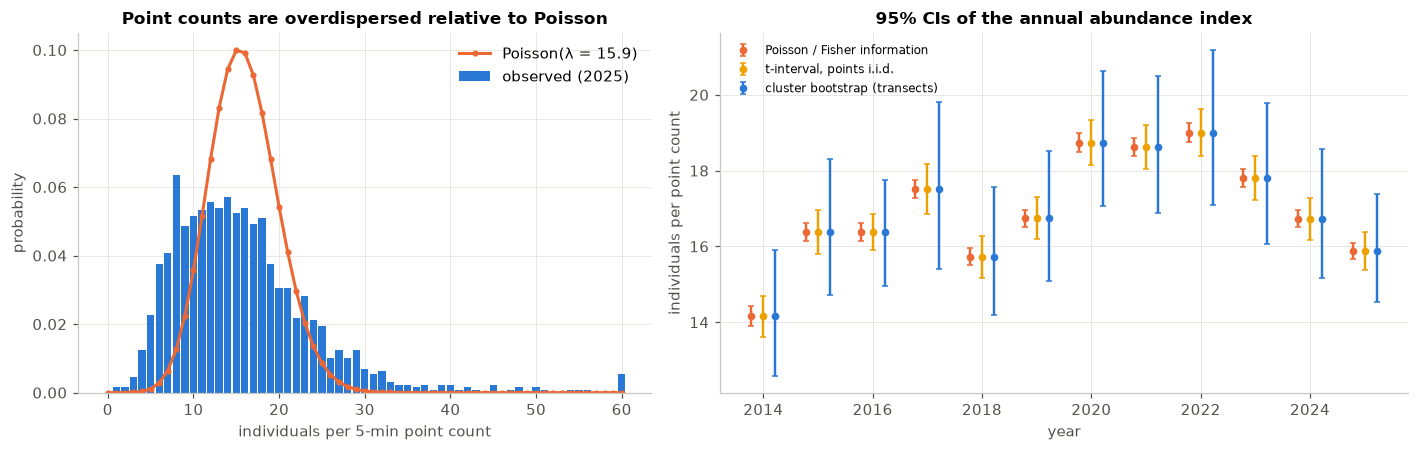

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 1.2]})
ax = axes[0]
kk = np.arange(0, 61)
emp = np.bincount(np.clip(y25.astype(int), 0, 60), minlength=61) / len(y25)
ax.bar(kk, emp, color=plots.PALETTE[0], width=0.85, label="observed (2025)")
ax.plot(kk, stats.poisson.pmf(kk, m_), color=plots.PALETTE[1], marker="o", markersize=3, label=f"Poisson(λ = {m_:.1f})")
ax.set(title="Point counts are overdispersed relative to Poisson", xlabel="individuals per 5-min point count",
       ylabel="probability")
ax.legend()
ax = axes[1]
yrs = ci_cmp.index.values
for off, (lab, lo, hi, col) in zip([-0.22, 0, 0.22], [
        ("Poisson / Fisher information", mean_t - 1.96 * se_pois, mean_t + 1.96 * se_pois, plots.PALETTE[1]),
        ("t-interval, points i.i.d.", mean_t - tq * se_t, mean_t + tq * se_t, plots.PALETTE[3]),
        ("cluster bootstrap (transects)", ab["ci_low"], ab["ci_high"], plots.PALETTE[0])]):
    ax.errorbar(yrs + off, mean_t, yerr=[mean_t - lo, hi - mean_t], fmt="o", color=col, markersize=4,
                capsize=2, lw=1.6, label=lab)
ax.set(title="95% CIs of the annual abundance index", xlabel="year", ylabel="individuals per point count")
ax.set_xticks(yrs[::2])
ax.legend(loc="upper left", fontsize=8)
fig.tight_layout()
plots.savefig(fig, "fig07_ci_methods")
plt.show()

**Reading.** The cluster-bootstrap standard errors are about **3 times** the i.i.d. ones and about
**7 times** the Poisson/Fisher ones: treating ~1,200 correlated, overdispersed point counts as
independent Poisson draws grossly overstates the precision. All confidence intervals below are
**95 % cluster-bootstrap intervals** ($B$ = 2000 for indices, 1000 for regression coefficients,
seed fixed in `config.py`). Percentile intervals are used by default; the basic (reflection)
interval has the same width by construction and differs only when the bootstrap distribution
is off-centre. For island-wide (rarefied) richness neither interval is valid, because the
bootstrap itself is biased there (a duplicated transect adds no new species), so a
delete-one-transect jackknife is used instead (next section).

## 3. Annual estimates 2014–2025 for the four indicators

In [7]:
# Indicator 2: richness per complete visit (ratio: total species-per-visit / number of visits)
vc = v[v["complete"]].assign(one=1.0)
rich, rich_reps = I.annual_ratio_index(vc, "richness", "one", B=B_INDEX, seed=C.SEED)

# Indicator 3: rarefied richness with m visits, bootstrapped with the same transect weights
sp_vis = rec[rec["is_species"]].groupby(["transect", "year", "species"])["visit_id"].nunique()
species_list = sorted(sp_vis.index.get_level_values("species").unique())
tr_list = sorted(v["transect"].unique()); yr_list = sorted(v["year"].unique())
inc = (sp_vis.unstack("species").reindex(columns=species_list)
       .reindex(pd.MultiIndex.from_product([tr_list, yr_list])).fillna(0).to_numpy()
       .reshape(len(tr_list), len(yr_list), len(species_list)))                 # visits with species s
nvis = (v.groupby(["transect", "year"]).size().reindex(pd.MultiIndex.from_product([tr_list, yr_list]))
        .fillna(0).to_numpy().reshape(len(tr_list), len(yr_list)))               # visits per transect-year
M_RARE = 60
raw_total = (inc.sum(0) > 0).sum(1)
rare_est = I.rarefied_richness(inc.sum(0), nvis.sum(0), M_RARE)
W = I.cluster_weights(len(tr_list), B_INDEX, C.SEED)
inc_b = np.einsum("bk,kts->bts", W, inc)
nvis_b = W @ nvis
rare_reps = I.rarefied_richness(inc_b, nvis_b, M_RARE)
raw_reps = (inc_b > 0).sum(-1).astype(float)
print(f"Rarefaction to m = {M_RARE} visits; bootstrap replicates with fewer than m visits in a year: "
      f"{np.isnan(rare_reps).mean():.2%} (dropped)")
# The cluster bootstrap FAILS for richness: a transect drawn twice adds visits but never new
# species, so every bootstrap replicate under-states richness and the bootstrap distribution
# sits below the estimate.
rare_bias = np.nanmean(rare_reps, axis=0) - rare_est
p_lo, p_hi = I.percentile_ci(rare_reps)
print(f"Bootstrap bias of rarefied richness: {rare_bias.mean():.1f} species on average; the estimate lies "
      f"inside its own percentile interval in only {np.mean((p_lo <= rare_est) & (rare_est <= p_hi)):.0%} of years.")
# Remedy: delete-one-transect jackknife (no duplicated sites). SE_jack = sqrt((K-1)/K * sum (theta_-k - mean)^2),
# then a normal interval (CLT). The same jackknife is used for the raw species total.
K = len(tr_list)
inc_tot, nvis_tot = inc.sum(0), nvis.sum(0)
jk_rare = np.array([I.rarefied_richness(inc_tot - inc[k], nvis_tot - nvis[k], M_RARE) for k in range(K)])
jk_raw = np.array([((inc_tot - inc[k]) > 0).sum(-1) for k in range(K)], float)
def jk_se(j):
    return np.sqrt((K - 1) / K * ((j - j.mean(0)) ** 2).sum(0))
z = stats.norm.ppf(0.5 + LEVEL / 2)
rare_se = jk_se(jk_rare)
rare_lo, rare_hi = rare_est - z * rare_se, rare_est + z * rare_se
print(f"Jackknife SE of rarefied richness: {rare_se.min():.2f}-{rare_se.max():.2f} species across years")

# Indicator 4: composition shares (ratio of endemic or exotic individuals to all individuals)
comp = comm.assign(endemic=lambda d: d["count"] * d["status_group"].eq("Endemic"),
                   exotic=lambda d: d["count"] * d["status_group"].eq("Exotic"))
end_, end_reps = I.annual_ratio_index(comp, "endemic", "count", B=B_INDEX, seed=C.SEED)
exo_, exo_reps = I.annual_ratio_index(comp, "exotic", "count", B=B_INDEX, seed=C.SEED)

def ci(reps):
    lo, hi = I.percentile_ci(reps, LEVEL)
    return lo, hi

ind_tab = pd.DataFrame({
    "abundance_index": ab["estimate"], "abundance_low": ab["ci_low"], "abundance_high": ab["ci_high"],
    "abundance_base100": ab["index100"], "base100_low": ab["index100_low"], "base100_high": ab["index100_high"],
    "richness_per_visit": rich["estimate"], "richness_low": rich["ci_low"], "richness_high": rich["ci_high"],
    "rarefied_richness_m60": rare_est, "rarefied_low": rare_lo, "rarefied_high": rare_hi,
    "raw_species_total": raw_total, "visits": nvis.sum(0),
    "endemic_share_pct": end_["estimate"] * 100, "endemic_low": end_["ci_low"] * 100, "endemic_high": end_["ci_high"] * 100,
    "exotic_share_pct": exo_["estimate"] * 100, "exotic_low": exo_["ci_low"] * 100, "exotic_high": exo_["ci_high"] * 100,
}, index=pd.Index(yr_list, name="year"))
ind_tab.to_csv(C.RES_DIR / "table09_annual_indicators.csv")
ind_tab.round(2).T

Rarefaction to m = 60 visits; bootstrap replicates with fewer than m visits in a year: 0.05% (dropped)
Bootstrap bias of rarefied richness: -3.2 species on average; the estimate lies inside its own percentile interval in only 83% of years.
Jackknife SE of rarefied richness: 2.19-3.68 species across years


year,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
abundance_index,14.16,16.38,16.39,17.52,15.73,16.75,18.73,18.63,19.00,17.80,16.73,15.88
abundance_low,12.57,14.71,14.95,15.41,14.19,15.10,17.07,16.88,17.08,16.08,15.17,14.54
abundance_high,15.90,18.32,17.75,19.82,17.56,18.52,20.63,20.50,21.19,19.78,18.58,17.39
abundance_base100,100.00,115.74,115.77,123.80,111.10,118.30,132.34,131.59,134.25,125.75,118.16,112.18
base100_low,100.00,105.83,105.75,109.13,100.59,106.57,120.21,118.22,120.67,112.60,106.50,101.23
base100_high,100.00,126.11,126.48,139.79,122.82,131.68,146.07,145.49,150.03,140.13,130.81,124.23
richness_per_visit,16.70,18.40,18.95,18.65,18.54,18.64,19.93,19.51,19.14,19.19,18.66,18.72
richness_low,15.86,17.58,18.14,17.79,17.79,17.80,19.19,18.72,18.17,18.38,17.92,17.97
richness_high,17.60,19.21,19.70,19.43,19.29,19.47,20.59,20.27,20.02,19.95,19.34,19.46
rarefied_richness_m60,56.66,58.21,60.05,56.80,58.12,57.48,61.62,58.60,58.00,56.53,58.93,60.73


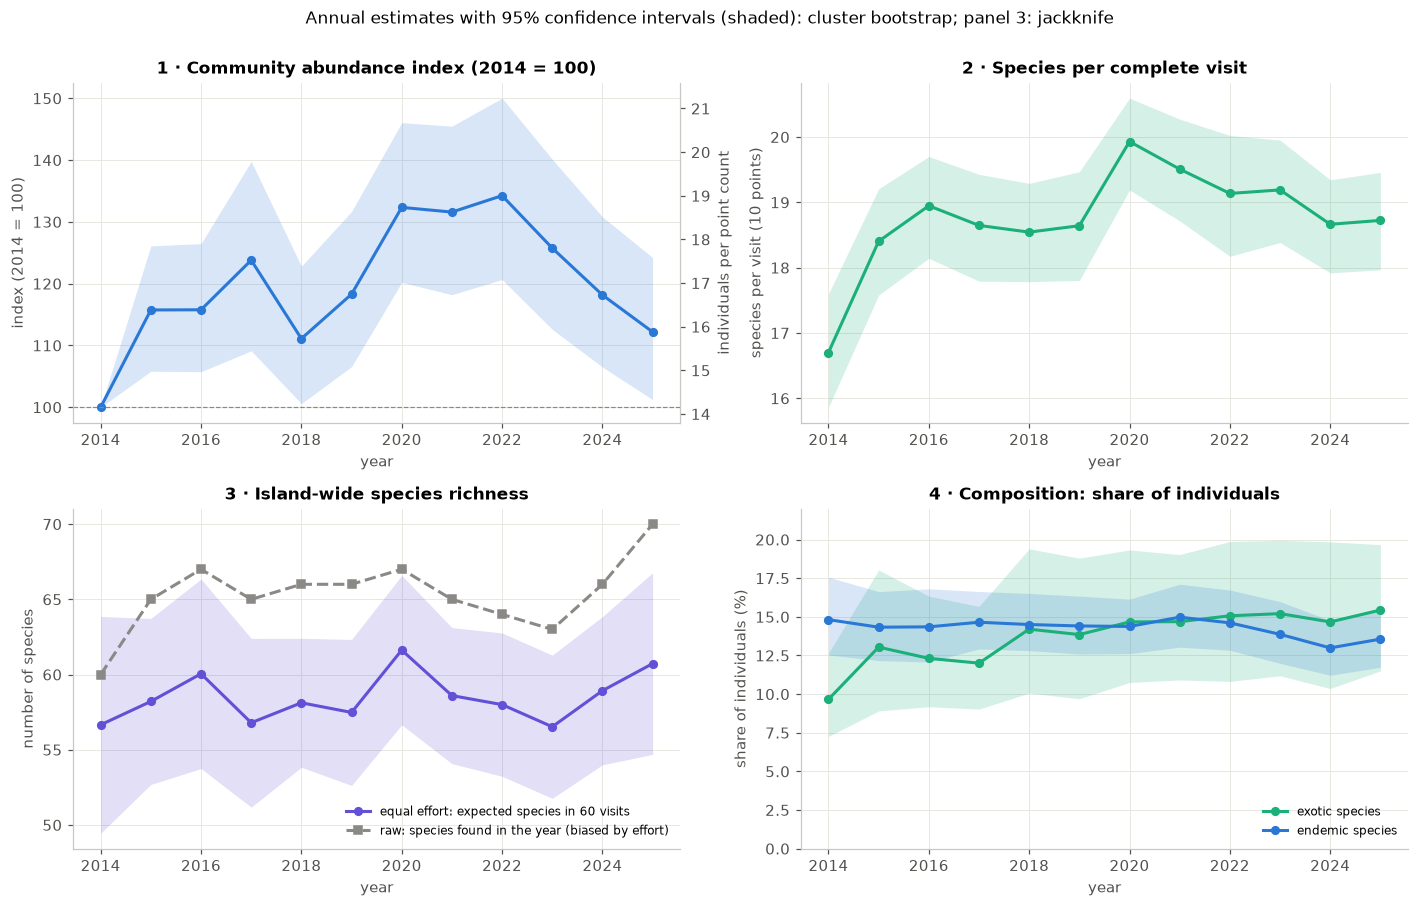

In [8]:
def band(ax, x, est, lo, hi, color, label=None, marker="o"):
    ax.fill_between(x, lo, hi, color=color, alpha=0.18, linewidth=0)
    ax.plot(x, est, marker=marker, color=color, label=label, markersize=5)

fig, axes = plt.subplots(2, 2, figsize=(13, 8.2))
x = np.array(yr_list)
ax = axes[0, 0]
band(ax, x, ind_tab["abundance_base100"], ind_tab["base100_low"], ind_tab["base100_high"], plots.PALETTE[0])
ax.axhline(100, color=plots.GREY, lw=0.8, ls="--")
ax.set(title="1 · Community abundance index (2014 = 100)", ylabel="index (2014 = 100)")
ax2 = ax.secondary_yaxis("right", functions=(lambda z: z * ab["estimate"].iloc[0] / 100,
                                              lambda z: z / ab["estimate"].iloc[0] * 100))
ax2.set_ylabel("individuals per point count")

ax = axes[0, 1]
band(ax, x, ind_tab["richness_per_visit"], ind_tab["richness_low"], ind_tab["richness_high"], plots.PALETTE[2])
ax.set(title="2 · Species per complete visit", ylabel="species per visit (10 points)")

ax = axes[1, 0]
band(ax, x, ind_tab["rarefied_richness_m60"], ind_tab["rarefied_low"], ind_tab["rarefied_high"], plots.PALETTE[6],
     label=f"equal effort: expected species in {M_RARE} visits")
ax.plot(x, ind_tab["raw_species_total"], marker="s", color=plots.GREY, ls="--", markersize=5,
        label="raw: species found in the year (biased by effort)")
ax.set(title="3 · Island-wide species richness", ylabel="number of species")
ax.legend(loc="lower right", fontsize=8)

ax = axes[1, 1]
band(ax, x, ind_tab["exotic_share_pct"], ind_tab["exotic_low"], ind_tab["exotic_high"], plots.STATUS_COLORS["Exotic"], label="exotic species")
band(ax, x, ind_tab["endemic_share_pct"], ind_tab["endemic_low"], ind_tab["endemic_high"], plots.STATUS_COLORS["Endemic"], label="endemic species")
ax.set(title="4 · Composition: share of individuals", ylabel="share of individuals (%)", ylim=(0, 22))
ax.legend(loc="lower right", fontsize=8)
for ax in axes.flat:
    ax.set_xlabel("year"); ax.set_xticks(x[::2])
fig.suptitle("Annual estimates with 95% confidence intervals (shaded): cluster bootstrap; panel 3: jackknife", fontsize=11, y=1.0)
fig.tight_layout()
plots.savefig(fig, "fig08_indicators")
plt.show()

**Reading.**
1. **Abundance** rises from 2014 to a plateau in 2020–2022 (≈ +32–34 % relative to 2014), then
   falls back to ≈ +12 % in 2025. Its CI is wide (about ±11 points in 2025) because only 65 transects carry
   independent information.
2. **Local richness** (species per visit) moves little: ≈ 16.7 species in 2014, 18.4–19.9 afterwards.
3. **Island-wide richness** (CI: jackknife, because the bootstrap is biased for richness — see the
   printed check above): the raw number of species found rises from 60 to 70, but this is an
   effort artefact — 2014 had 78 visits, 2025 had 129. At equal effort (60 visits per year) the
   expected richness stays between 56.5 and 61.6 species with widely overlapping CIs: no
   evidence of a change in the island's species pool. This is the **bias** of the raw estimator
   made visible.
4. **Composition**: the share of individuals from **exotic species rises from ≈ 10 % to ≈ 15 %**,
   while the endemic share is stable around 14–15 % and dips slightly in 2023–2025.

The 2014 values are systematically low on several indicators. 2014 is also the year with
fewest transects and all observers new to the programme; the models below examine how much of
the apparent change survives once these factors are accounted for.

## 4. Trend models for the abundance index

### 4.1 Response and scale
Unit = transect visit (1,420 visits). Response = $\log$(individuals per point count). Notebook 01
showed that on this scale the residual spread no longer grows with the mean and the skewness
disappears, so a linear model with constant variance is reasonable, and the year coefficient
$\beta$ translates into a rate of change of $100(e^{\beta}-1)$ % per year. Incomplete visits are
kept: the response is already a per-point average.

### 4.2 A ladder of specifications
Each model adds one block of explanatory variables; the change in the year coefficient between
two models measures how much of the naive trend was due to the added block (omitted-variable
bias in the smaller model).

| Model | Regressors | Question |
|---|---|---|
| M0 | annual index (12 points) ~ year | naive trend of the annual series |
| M1 | visit-level ~ year | pooled visits, no adjustment |
| M2 | + transect fixed effects | which sites were surveyed (changing panel) |
| M3 | + survey conditions (day of year, start time, passage, rain, wind) | when / in which weather |
| M4a | + observer fixed effects | who counted (observer reliability) |
| M4b | M3 + observer experience, log(1 + previous years) | learning (brief's suggestion) |
| M4c | M3 + first-year indicator | new-observer effect only |

Model comparison: adjusted $R^2$, log-likelihood/AIC/BIC (Gaussian likelihood),
and the **10-fold cross-validated mean squared prediction error** (out-of-sample MSE = bias² +
variance). Confidence intervals for the rate come from the cluster bootstrap.

In [9]:
specs = {
    "M1 pooled": dict(),
    "M2 + transect": dict(fixed_effects=["transect"]),
    "M3 + conditions": dict(numeric=COND, fixed_effects=["transect"]),
    "M4a + observer FE": dict(numeric=COND, fixed_effects=["transect", "observer"]),
    "M4b + experience": dict(numeric=COND + ["log_prev_seasons"], fixed_effects=["transect"]),
    "M4c + first year": dict(numeric=COND + ["first_season"], fixed_effects=["transect"]),
}

def other_builder(spec):
    """Regressors except intercept and transect dummies (for the fast within-transect bootstrap)."""
    fe = [f for f in spec.get("fixed_effects", []) if f != "transect"]
    def b(d):
        X, n = M.design(d, numeric=spec.get("numeric", ()), fixed_effects=fe)
        return X[:, 1:], n[1:]
    return b

rows, fits, boot = [], {}, {}
# M0: annual series
a0 = ab.reset_index().assign(ly=lambda d: np.log(d["estimate"]))
X0, n0 = M.design(a0)
f0 = M.OLSFit(X0, a0["ly"], n0)
slope_reps = np.polyfit(np.array(yr_list) - 2014, np.log(ab_reps).T, 1)[0]   # slope for every bootstrap series
lo0, hi0 = np.quantile(slope_reps, [0.025, 0.975])
rows.append({"model": "M0 annual series", "pct_per_year": M.pct_per_year(f0.coef("year")),
             "ci_low": M.pct_per_year(lo0), "ci_high": M.pct_per_year(hi0),
             "SE_classical": f0.se_of("year"), "SE_cluster_boot": slope_reps.std(ddof=1), **f0.summary_row()})
for name, spec in specs.items():
    build = lambda d, s=spec: M.design(d, **s)
    X, n = build(v)
    f = M.OLSFit(X, v["y"], n); fits[name] = f
    if "transect" in spec.get("fixed_effects", []):
        _, reps = M.cluster_bootstrap_within(v, other_builder(spec), "y", ["year"], B=B_COEF, seed=C.SEED)
    else:
        reps = M.cluster_bootstrap_coef(v, build, "y", ["year"], B=B_COEF, seed=C.SEED)
    boot[name] = reps[:, 0]
    lo, hi = np.quantile(reps[:, 0], [0.025, 0.975])
    cvm, cvse = M.cv_mse(v, build, "y", k=10, seed=C.SEED, stratify="transect")
    rows.append({"model": name, "pct_per_year": M.pct_per_year(f.coef("year")),
                 "ci_low": M.pct_per_year(lo), "ci_high": M.pct_per_year(hi),
                 "SE_classical": f.se_of("year"), "SE_cluster_boot": reps[:, 0].std(ddof=1),
                 **f.summary_row(), "CV_MSE": cvm, "CV_MSE_se": cvse})
ladder = pd.DataFrame(rows).set_index("model")
ladder.to_csv(C.RES_DIR / "table10_model_ladder.csv")
ladder[["pct_per_year", "ci_low", "ci_high", "SE_classical", "SE_cluster_boot", "parameters",
        "adj_R2", "AIC", "BIC", "CV_MSE", "CV_MSE_se"]].round(4)

,pct_per_year,ci_low,ci_high,SE_classical,SE_cluster_boot,parameters,adj_R2,AIC,BIC,CV_MSE,CV_MSE_se
model,,,,,,,,,,,
M0 annual series,1.0740,0.3132,1.8686,0.0067,0.0039,3,0.1233,-22.7373,-21.2826,NaN,NaN
M1 pooled,0.9090,0.2530,1.5766,0.0033,0.0034,3,0.0047,1509.3880,1525.1633,0.1693,0.0046
M2 + transect,0.9461,0.3390,1.5755,0.0018,0.0032,67,0.6913,-90.3765,261.9372,0.0551,0.0019
M3 + conditions,1.0852,0.4895,1.6617,0.0018,0.0030,72,0.7113,-180.8486,197.7571,0.0517,0.0019
M4a + observer FE,0.7350,0.2399,1.2489,0.0019,0.0025,108,0.7483,-342.1458,225.7627,0.0458,0.0016
M4b + experience,-0.0949,-1.2107,0.8238,0.0029,0.0053,73,0.7165,-205.9819,177.8822,0.0509,0.0020
M4c + first year,0.7720,0.1564,1.4014,0.0019,0.0032,73,0.7161,-203.9521,179.9120,0.0509,0.0019


In [10]:
f4b, f4c = fits["M4b + experience"], fits["M4c + first year"]
print(f"M4b: experience coefficient {f4b.coef('log_prev_seasons'):.3f} per unit of log(1+years) "
      f"(+{M.pct_per_year(f4b.coef('log_prev_seasons') * np.log(2)):.1f} % for a doubling of experience)")
print(f"M4c: first-year observers count {M.pct_per_year(f4c.coef('first_season')):.1f} % individuals "
      f"(classical SE {f4c.se_of('first_season'):.3f})")
r_ = np.corrcoef(v["year"], v["log_prev_seasons"])[0, 1]
print(f"corr(year, log experience) = {r_:.2f} -> variance inflation of the year coefficient ~ {1 / (1 - r_ ** 2):.1f}; "
      f"bootstrap SE of year: M3 {ladder.loc['M3 + conditions', 'SE_cluster_boot']:.4f} vs M4b "
      f"{ladder.loc['M4b + experience', 'SE_cluster_boot']:.4f}")
print(f"Classical vs cluster-bootstrap SE of the year coefficient (M3): "
      f"{ladder.loc['M3 + conditions', 'SE_classical']:.4f} vs {ladder.loc['M3 + conditions', 'SE_cluster_boot']:.4f}")

M4b: experience coefficient 0.072 per unit of log(1+years) (+5.1 % for a doubling of experience)
M4c: first-year observers count -10.8 % individuals (classical SE 0.023)
corr(year, log experience) = 0.77 -> variance inflation of the year coefficient ~ 2.5; bootstrap SE of year: M3 0.0030 vs M4b 0.0053
Classical vs cluster-bootstrap SE of the year coefficient (M3): 0.0018 vs 0.0030


**Reading — what the ladder tells us.**

* **Fit.** Transect identity explains most of the variation (adjusted $R^2$ jumps from ≈ 0 to
  0.69): sites differ much more from each other than years do. Survey conditions and observer
  identity each improve the fit further; the cross-validated error decreases at every step up to
  M4a, so the extra parameters are not over-fitting: their gain in bias exceeds their cost in
  variance.
* **Observers bias the naive trend.** Adding observer fixed effects lowers the estimated rate from
  ≈ +1.1 % to ≈ +0.7 % per year. About a third of the trend estimated by M3 is therefore
  attributable to *who* counted — consistent with notebook 01, where the most active observer's
  share of visits peaks exactly when the raw index peaks.
* **Experience is nearly collinear with time.** In M4b the experience term absorbs the whole trend
  (rate ≈ 0): because the core observers stayed for 12 years, "more experienced" and "later"
  are almost the same variable (correlation 0.77 with log-experience), and the bootstrap
  standard error of the year coefficient almost doubles (0.0053 vs 0.0030). The data cannot separate "observers improved" from "birds increased" with this
  variable; M4b is a cautionary example of the bias–variance trade-off rather than a credible
  estimate. The **first-year indicator** (M4c), which does not grow with time, is identifiable:
  observers in their first year record ≈ 11 % fewer individuals.
* **Uncertainty.** The classical (independence-based) SE is ≈ 1.7× smaller than the cluster
  bootstrap SE; only the latter is used for intervals.

We retain **M4a** (transect + conditions + observer fixed effects) as the main specification:
best AIC and best cross-validated error. BIC, which penalises the 36 observer parameters more
heavily, prefers the leaner M4b/M4c; this disagreement is itself informative and is why the
sensitivity of the rate to the observer specification is reported rather than hidden.

### 4.3 Is a straight line the right shape?
A single rate of change is easy to communicate, but the annual series rises and then falls.
Below, the linear year term of M3 and M4a is replaced by a quadratic and by one coefficient per
year (most flexible: annual adjusted indices).

In [11]:
shape_rows = []
for fe_name, fe in [("transect", ["transect"]), ("transect + observer", ["transect", "observer"])]:
    for shape, kw in [("linear", dict(year_poly=1)), ("quadratic", dict(year_poly=2)), ("year factor", dict(year_as_factor=True))]:
        build = lambda d, kw=kw, fe=fe: M.design(d, numeric=COND, fixed_effects=fe, **kw)
        X, n = build(v); f = M.OLSFit(X, v["y"], n)
        cvm, cvse = M.cv_mse(v, build, "y", k=10, seed=C.SEED, stratify="transect")
        shape_rows.append({"fixed effects": fe_name, "year shape": shape, "parameters": f.rank + 1,
                           "adj_R2": f.adj_r2, "AIC": f.aic, "BIC": f.bic, "CV_MSE": cvm, "CV_MSE_se": cvse})
shapes = pd.DataFrame(shape_rows).set_index(["fixed effects", "year shape"])
shapes.to_csv(C.RES_DIR / "table11_trend_shape.csv")
shapes.round(4)

parameters  adj_R2       AIC       BIC  CV_MSE  CV_MSE_se
fixed effects       year shape                                                            
transect            linear               72  0.7113 -180.8486  197.7571  0.0517     0.0019
                    quadratic            73  0.7209 -228.0646  155.7995  0.0500     0.0019
                    year factor          82  0.7287 -259.5732  171.6166  0.0488     0.0020
transect + observer linear              108  0.7483 -342.1458  225.7627  0.0458     0.0016
                    quadratic           109  0.7542 -374.5948  198.5721  0.0446     0.0016
                    year factor         118  0.7583 -390.3128  230.1798  0.0440     0.0015

In [12]:
# Residual means by year under the linear M4a: a systematic pattern = misspecified shape
res_lin = pd.Series(fits["M4a + observer FE"].resid).groupby(v["year"].to_numpy()).agg(["mean", "size", "std"])
res_lin["se"] = res_lin["std"] / np.sqrt(res_lin["size"])

# Adjusted annual indices (year as factor) with cluster-bootstrap CIs, for M3 and M4a
adj = {}
for name, fe in [("M3", []), ("M4a", ["observer"])]:
    def ob(d, fe=fe):
        X, n = M.design(d, numeric=COND, fixed_effects=fe, year_as_factor=True)
        return X[:, 1:], n[1:]
    yr_names = [f"year[{y}]" for y in yr_list[1:]]
    est, reps = M.cluster_bootstrap_within(v, ob, "y", yr_names, B=B_COEF, seed=C.SEED)
    lo, hi = np.quantile(reps, [0.025, 0.975], axis=0)
    adj[name] = pd.DataFrame({"index100": 100 * np.exp(np.r_[0, est]), "low": 100 * np.exp(np.r_[0, lo]),
                              "high": 100 * np.exp(np.r_[0, hi])}, index=yr_list)
adj_tab = pd.concat({"raw": ab[["index100", "index100_low", "index100_high"]].set_axis(["index100", "low", "high"], axis=1),
                     "adjusted M3 (sites + conditions)": adj["M3"], "adjusted M4a (+ observers)": adj["M4a"]}, axis=1)
adj_tab.to_csv(C.RES_DIR / "table12_adjusted_indices.csv")
adj_tab.round(1)

raw               adjusted M3 (sites + conditions)               adjusted M4a (+ observers)              
     index100    low   high                         index100    low   high                   index100    low   high
2014    100.0  100.0  100.0                            100.0  100.0  100.0                      100.0  100.0  100.0
2015    115.7  105.8  126.1                            114.2  106.1  122.9                      113.0  105.3  120.9
2016    115.8  105.8  126.5                            114.2  105.3  122.7                      114.4  105.9  122.6
2017    123.8  109.1  139.8                            117.5  106.2  129.3                      117.6  106.5  129.2
2018    111.1  100.6  122.8                            110.6  101.3  120.4                      110.3  101.9  119.4
2019    118.3  106.6  131.7                            117.3  106.5  128.0                      116.1  106.0  126.6
2020    132.3  120.2  146.1                            129.2  118.9  139.3                      123.3  114.9  132.7
2021    131.6  118.2  145.5                            129.3  117.3  141.1                      123.0  113.3  133.8
2022    134.2  120.7  150.0                            130.0  118.7  141.5                      125.6  115.9  135.6
2023    125.8  112.6  140.1                            123.4  112.1  134.7                      119.8  110.4  129.1
2024    118.2  106.5  130.8                            118.2  108.5  128.3                      115.9  107.3  125.2
2025    112.2  101.2  124.2                            115.3  105.4  125.4                      112.6  104.4  122.1

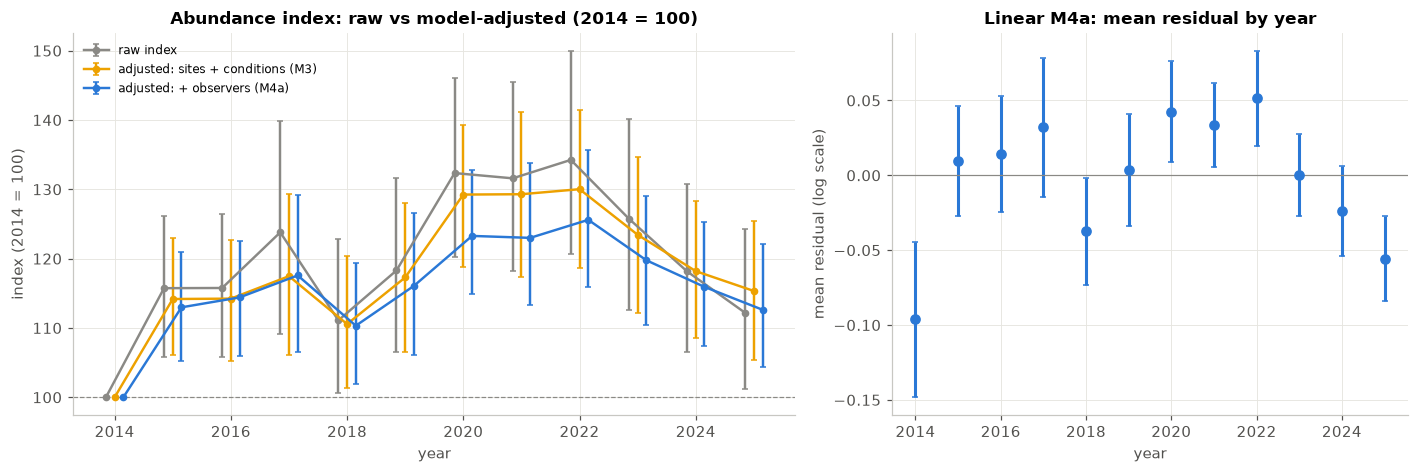

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1.4, 1]})
ax = axes[0]
for (lab, d), col, off in zip([("raw index", adj_tab["raw"]), ("adjusted: sites + conditions (M3)", adj["M3"]),
                               ("adjusted: + observers (M4a)", adj["M4a"])],
                              [plots.GREY, plots.PALETTE[3], plots.PALETTE[0]], [-0.15, 0, 0.15]):
    ax.errorbar(x + off, d["index100"], yerr=[d["index100"] - d["low"], d["high"] - d["index100"]],
                fmt="-o", color=col, markersize=4, capsize=2, lw=1.6, label=lab)
ax.axhline(100, color=plots.GREY, lw=0.8, ls="--")
ax.set(title="Abundance index: raw vs model-adjusted (2014 = 100)", xlabel="year", ylabel="index (2014 = 100)")
ax.set_xticks(x[::2]); ax.legend(loc="upper left", fontsize=8)
ax = axes[1]
ax.errorbar(res_lin.index, res_lin["mean"], yerr=1.96 * res_lin["se"], fmt="o", color=plots.PALETTE[0], capsize=2)
ax.axhline(0, color=plots.GREY, lw=0.8)
ax.set(title="Linear M4a: mean residual by year", xlabel="year", ylabel="mean residual (log scale)")
ax.set_xticks(x[::2])
fig.tight_layout()
plots.savefig(fig, "fig09_adjusted_index")
plt.show()

**Reading.** The residuals of the linear model are not centred on zero by year: negative in
2014 and 2024–2025, positive in 2020–2022. A straight line is a **biased** description of this
series. The quadratic and year-factor specifications fit better on AIC and cross-validated MSE; BIC
also prefers the quadratic shape, but penalises the year factor once observers are included. The shape — an increase to 2020–2022 followed by a decline — is a
feature of the data, not noise. The year-factor model is the most flexible (lowest bias) but
each annual value is estimated less precisely (wider intervals): the usual trade-off.

Adjusting for sites and conditions barely changes the curve, but adjusting for observers
**flattens the 2020–2022 peak** (from ≈ 130 to ≈ 125): part of that peak was due to the observer
mix. After all adjustments, abundance in 2025 is ≈ 13 % above 2014 (95 % CI 104–122); given that
2014 is a ramp-up year, the safest summary is **"stable to slightly increasing over 2014–2025,
with a transient maximum around 2020–2022"**.

### 4.4 Diagnostics of the retained model (M4a, year as factor)

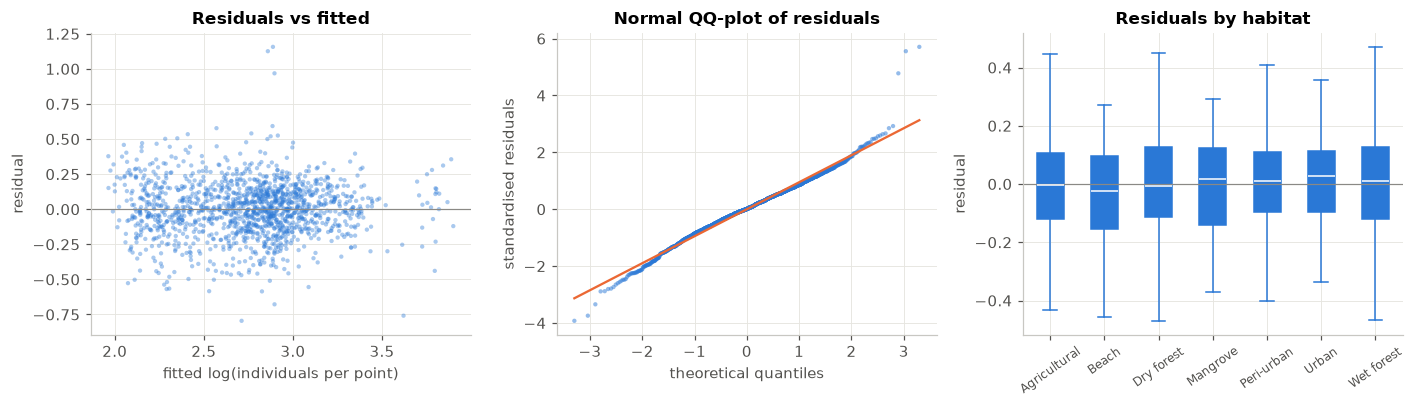

Residual skewness 0.11, excess kurtosis 2.36; corr(|residual|, fitted) = -0.11


In [14]:
Xf, nf = M.design(v, numeric=COND, fixed_effects=["transect", "observer"], year_as_factor=True)
ff = M.OLSFit(Xf, v["y"], nf)
std_res = ff.resid / np.sqrt(ff.sigma2)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
ax = axes[0]
ax.scatter(ff.fitted, ff.resid, s=8, alpha=0.4, color=plots.PALETTE[0], edgecolor="none")
ax.axhline(0, color=plots.GREY, lw=0.8)
ax.set(title="Residuals vs fitted", xlabel="fitted log(individuals per point)", ylabel="residual")
ax = axes[1]
(osm, osr), (slope_, icpt_, _) = stats.probplot(std_res, dist="norm")
ax.scatter(osm, osr, s=8, alpha=0.5, color=plots.PALETTE[0], edgecolor="none")
ax.plot(osm, icpt_ + slope_ * osm, color=plots.PALETTE[1], lw=1.5)
ax.set(title="Normal QQ-plot of residuals", xlabel="theoretical quantiles", ylabel="standardised residuals")
ax = axes[2]
by_tr = pd.Series(ff.resid).groupby(v["habitat"].to_numpy())
data = [g.to_numpy() for _, g in by_tr]
ax.boxplot(data, tick_labels=[h for h, _ in by_tr], patch_artist=True, showfliers=False,
           medianprops=dict(color="white"), boxprops=dict(facecolor=plots.PALETTE[0], edgecolor=plots.PALETTE[0]),
           whiskerprops=dict(color=plots.PALETTE[0]), capprops=dict(color=plots.PALETTE[0]))
ax.axhline(0, color=plots.GREY, lw=0.8)
ax.set(title="Residuals by habitat", ylabel="residual")
ax.tick_params(axis="x", rotation=35, labelsize=8)
fig.tight_layout()
plots.savefig(fig, "fig10_diagnostics")
plt.show()
print(f"Residual skewness {stats.skew(ff.resid):.2f}, excess kurtosis {stats.kurtosis(ff.resid):.2f}; "
      f"corr(|residual|, fitted) = {np.corrcoef(np.abs(ff.resid), ff.fitted)[0, 1]:.2f}")

**Reading.** Residuals show no trend or funnel against the fitted values (constant variance on
the log scale is reasonable), are centred in every habitat, and are close to normal in the bulk
with slightly heavy tails (a few visits with flocks). Since the intervals come from the
bootstrap and not from the normal approximation, the mild tail departure does not affect them.

### 4.5 A simulation: how large is the observer bias?
We generate data with **no trend at all** but with the estimated transect, condition and
observer effects of M4a and the real survey design (who surveyed which transect when), plus
normal noise with the residual SD. We then estimate the trend with M3 (ignores observers) and
with M4a.

In [15]:
rng = np.random.default_rng(C.SEED)
Xs, ns = M.design(v, numeric=COND, fixed_effects=["transect", "observer"])
fs = M.OLSFit(Xs, v["y"], ns)
beta0 = fs.beta.copy(); beta0[ns.index("year")] = 0.0          # true trend = 0
mu0 = Xs @ beta0
X3, n3 = M.design(v, numeric=COND, fixed_effects=["transect"])
sim = []
for _ in range(500):
    ysim = mu0 + rng.normal(0, np.sqrt(fs.sigma2), len(v))
    b3 = np.linalg.lstsq(X3, ysim, rcond=None)[0][n3.index("year")]
    b4 = np.linalg.lstsq(Xs, ysim, rcond=None)[0][ns.index("year")]
    sim.append((b3, b4))
sim = M.pct_per_year(np.array(sim))
sim_tab = pd.DataFrame({"mean estimate (%/yr)": sim.mean(0), "bias (true = 0)": sim.mean(0),
                        "SD across simulations": sim.std(0, ddof=1),
                        "MSE": (sim ** 2).mean(0)}, index=["M3 (ignores observers)", "M4a (observer FE)"])
sim_tab.round(3)

,mean estimate (%/yr),bias (true = 0),SD across simulations,MSE
M3 (ignores observers),0.353,0.353,0.171,0.154
M4a (observer FE),0.005,0.005,0.198,0.039


**Reading.** With no true change in birds, the model that ignores observers still finds a trend of
≈ +0.35 % per year — the size of the gap between M3 and M4a on the real data — purely because the
mix of observers changed over time. M4a is unbiased; its variance is only slightly larger, so its
MSE is much lower. This is the bias–variance decomposition (MSE = bias² + variance) applied to our
own design, and it justifies the observer terms.

### 4.6 Robustness of the rate of change (M4a, linear)

In [16]:
def m4a_rate(d, ycol="y"):
    def ob(dd):
        X, n = M.design(dd, numeric=COND, fixed_effects=["observer"])
        return X[:, 1:], n[1:]
    est, reps = M.cluster_bootstrap_within(d, ob, ycol, ["year"], B=B_COEF, seed=C.SEED)
    lo, hi = np.quantile(reps[:, 0], [0.025, 0.975])
    return M.pct_per_year(est[0]), M.pct_per_year(lo), M.pct_per_year(hi)

rob = {
    "all visits (main)": m4a_rate(v),
    "core panel only (40 transects, every year)": m4a_rate(v[v["core_transect"]]),
    "birds within 50 m only": m4a_rate(v, "y50"),
    "complete visits only": m4a_rate(v[v["complete"]]),
    "excluding 2014 (ramp-up year)": m4a_rate(v[v["year"] > 2014]),
    "excluding visits flagged with both passages on one date": m4a_rate(v[~v["same_day_passages"]]),
}
rob_tab = pd.DataFrame(rob, index=["pct_per_year", "ci_low", "ci_high"]).T
rob_tab.to_csv(C.RES_DIR / "table13_robustness.csv")
rob_tab.round(2)

,pct_per_year,ci_low,ci_high
all visits (main),0.74,0.24,1.25
"core panel only (40 transects, every year)",0.49,-0.07,1.02
birds within 50 m only,0.28,-0.40,0.91
complete visits only,0.67,0.16,1.18
excluding 2014 (ramp-up year),0.30,-0.23,0.88
excluding visits flagged with both passages on one date,0.74,0.22,1.26


**Reading.** The positive linear rate is **fragile**. It is unchanged when using complete visits
only or dropping the flagged visits, but it shrinks to ≈ +0.5 % on the core panel, to ≈ +0.3 %
when 2014 is excluded, and to ≈ +0.3 % when only birds within 50 m are counted; in these three
cases the interval includes zero. The last result links to notebook 01: the share of birds
detected beyond 100 m rose from ~3 % to ~7 %, so part of the apparent increase may be a change in
*detection* (observers recording more distant birds) rather than in abundance. Robust conclusions:
**no decline** over 2014–2025, and a temporary maximum around 2020–2022.

## 5. Trends of the other indicators

In [17]:
def slope_ci(series, reps, log=False, basic=False):
    """OLS slope per year of an annual series, with CI from the bootstrap replicate series
    (percentile, or basic/reflection when the bootstrap distribution is biased)."""
    t = np.array(yr_list) - 2014
    yv = np.log(series) if log else np.asarray(series, float)
    R = np.log(reps) if log else reps
    ok = ~np.isnan(R).any(1)
    est = np.polyfit(t, yv, 1)[0]
    sl = np.polyfit(t, R[ok].T, 1)[0]
    lo, hi = np.quantile(sl, [0.025, 0.975])
    if basic:
        lo, hi = 2 * est - hi, 2 * est - lo
    return est, lo, hi

rows = []
# richness per complete visit: visit-level M3 and M4a (species per year)
for name, fe in [("M3", []), ("M4a", ["observer"])]:
    def ob(d, fe=fe):
        X, n = M.design(d, numeric=COND, fixed_effects=fe)
        return X[:, 1:], n[1:]
    est, reps = M.cluster_bootstrap_within(vc, ob, "richness", ["year"], B=B_COEF, seed=C.SEED)
    lo, hi = np.quantile(reps[:, 0], [0.025, 0.975])
    rows.append({"indicator": f"species per visit, {name}", "unit": "species / year", "slope": est[0], "ci_low": lo, "ci_high": hi})
# richness indicators: slope with a delete-one-transect jackknife SE (bootstrap is biased here, see section 3)
t_ = np.array(yr_list) - 2014
for lab, est_, jk in [("rarefied island richness (m = 60)", rare_est, jk_rare),
                      ("raw species total (effort-biased)", raw_total.astype(float), jk_raw)]:
    e = np.polyfit(t_, est_, 1)[0]
    sl = np.polyfit(t_, jk.T, 1)[0]
    se = np.sqrt((K - 1) / K * ((sl - sl.mean()) ** 2).sum())
    rows.append({"indicator": lab + " [jackknife]", "unit": "species / year", "slope": e, "ci_low": e - z * se, "ci_high": e + z * se})
for lab, est_, reps_ in [("exotic share", exo_["estimate"], exo_reps), ("endemic share", end_["estimate"], end_reps)]:
    e, l, h = slope_ci(est_ * 100, reps_ * 100)
    rows.append({"indicator": lab, "unit": "percentage points / year", "slope": e, "ci_low": l, "ci_high": h})
# composition on the core panel only (fixed set of sites)
core_tr = set(v.loc[v["core_transect"], "transect"])
for lab, col in [("exotic share, core panel", "exotic"), ("endemic share, core panel", "endemic")]:
    cc = comp[comp["transect"].isin(core_tr)]
    est_, reps_ = I.annual_ratio_index(cc, col, "count", B=B_INDEX, seed=C.SEED)
    e, l, h = slope_ci(est_["estimate"] * 100, reps_ * 100)
    rows.append({"indicator": lab, "unit": "percentage points / year", "slope": e, "ci_low": l, "ci_high": h})
other_tab = pd.DataFrame(rows).set_index("indicator")
other_tab.to_csv(C.RES_DIR / "table14_other_indicator_trends.csv")
other_tab.round(3)

,unit,slope,ci_low,ci_high
indicator,,,,
"species per visit, M3",species / year,0.093,0.034,0.146
"species per visit, M4a",species / year,0.034,-0.019,0.085
rarefied island richness (m = 60) [jackknife],species / year,0.133,-0.325,0.592
raw species total (effort-biased) [jackknife],species / year,0.294,-0.390,0.977
exotic share,percentage points / year,0.406,0.181,0.614
endemic share,percentage points / year,-0.098,-0.234,0.027
"exotic share, core panel",percentage points / year,0.453,0.157,0.737
"endemic share, core panel",percentage points / year,-0.101,-0.236,0.030


**Reading.**
* **Species per visit** increases by ≈ 0.09 species per year in the model without observers, but
  only ≈ 0.03 (interval including zero) once observers are accounted for — local richness is
  essentially stable, and the naive increase was largely an observer effect.
* **Island richness at equal effort** changes by ≈ +0.13 species per year, less than half the slope
  of the raw species total (≈ +0.29); both intervals include zero. The level comparison in
  section 3 is the clearer illustration: the raw total rises with effort (60 → 70 species) while
  the equal-effort estimate does not — an estimator whose bias depends on sample size.
* **Exotic share** increases by ≈ 0.4 percentage points per year (95 % CI 0.2–0.6), and the
  increase persists on the core panel (same 40 sites every year), so it is not explained by the
  addition of new transects. The endemic share declines slightly (≈ −0.1 point per year, interval
  including zero). Notebook 03 identifies which species drive these changes.

## 6. Summary of notebook 02

* **Uncertainty.** Point counts are neither Poisson nor independent; the transect-level cluster
  bootstrap gives standard errors ≈ 3× the i.i.d. and ≈ 7× the Poisson ones and is used
  throughout — except for island-wide (rarefied) richness, where resampling duplicates sites and biases the bootstrap
  downwards, so a delete-one-transect jackknife is used instead.
* **Abundance.** Raw index +32–34 % at the 2020–2022 peak, +12 % in 2025 versus 2014. After
  adjusting for sites, survey conditions and observers, the peak shrinks to ≈ +25 % and the
  long-run linear rate is ≈ +0.7 % per year (95 % CI 0.2–1.2), but this rate is fragile (low 2014
  year, far detections); the shape (rise, plateau, decline) is better described by a flexible
  year effect than by a straight line.
* **Observers matter.** About a third of the naive trend is due to the changing observer mix;
  a simulation with no true trend reproduces a bias of the same size. Observer experience is too
  collinear with time to be used as a regressor; new observers record ≈ 11 % fewer birds.
* **Diversity.** Local and island-wide richness are stable once effort and observers are
  accounted for; the apparent increase in the raw species total is an effort artefact.
* **Composition.** The share of exotic individuals rises (≈ 10 % → 15 %), robustly to the panel.